FSR is designed to show a roughly linear relationship on a log-log plot which translates to a power law equation:

$$R_{FSR}=kF^{-n}$$

Where $k$ is a scaling constant and $n$ is the sensors response exponent.

The measuring circuit is a voltage divider:

$$V_{out}=\frac{R_{fixed}}{R_{fixed}+R_{FSR}}V_{in}$$

Inserting the power law in into the voltage divider then gives:

$$V_{out}(F)=\frac{R_{fixed}}{R_{fixed}+kF^{-n}}V_{in}$$

The numerator and denominator is multiplied by $F^n$

$$V_{out}(F)=\frac{R_{fixed}\cdot F^n}{R_{fixed}\cdot F^n+k}V_{in}$$

Dividing both the numerator and denominator by $k$

$$V_{out}(F)=\frac{\frac{R_{fixed}}{k} F^n}{1+\frac{R_{fixed}}{k} F^n}V_{in}$$

And defining the constant $A=\frac{R_{fixed}}{k}$. The equation becomes:

$$V_{out}(F)=\frac{A F^n}{1+A F^n}V_{in}$$

This equation can be rewritten as the standard 2-parameter Hill equation by defining a half-saturation constant $K$ such that:

$$A=\frac{1}{K^n}$$

And inserting:

$$V_{out}(F)=\frac{\frac{1}{k^n} F^n}{1+\frac{1}{K^n} F^n}V_{in}$$

Multiplying the numerator and denominator by $K^n$ then gives:

$$V_{out}(F)=\frac{ F^n}{K^n+ F^n}V_{in}$$

Which is the standard 2-parameter Hill equation, where $V_{in}$ acts as the maximum possible voltage limit, $K$ is the half saturation constant, the exact force where voltage reaches half of $V_{in}$ and $n$ is the response exponent, also called the Hill coefficient.

In practice, when using the Hill equation, real-world parameters are added which extends the equation to the exteneded 4-parameter Hill equation. This is done because the voltage baseline is not exactly zero, when a zero force is applied, there is a tiny positive voltage $V_{offset}$ rather than $0V$. Similarly, the maximum is not quite $V_{in}$ due to internal minimum resistance floors in the FSR sensor.

$$V(F)=\frac{(V_{max}-V_{offset})\cdot F^n}{K^n+F^n}+V_{offset}$$

This equation currently calculates the voltage as a function of the force, but what is required is the force as a function of the output voltage. To convert the measured voltage into estimated force, the forward Hill model is algebraically solved for $F$.

Subtract $V_{offset}$ from both sides.

$$V-V_{offset}=\frac{(V_{max}-V_{offset})\cdot F^n}{K^n+F^n}$$

Multiply both sides by $(K^n+F^n)$ and group terms containing $F^n$

$$(V-V_{offset})K^n=(V_{max}-V)F^n$$

Isolate $F^n$

$$F^n=k^n\frac{V-V_{offset}}{V_{max}-V}$$

Take the $n$-th root to get $F$ as a function of $V$

$$F(V)=(k^n\frac{V-V_{offset}}{V_{max}-V})^{\frac{1}{n}}$$

$$F(V)=k(\frac{V-V_{offset}}{V_{max}-V})^{\frac{1}{n}}$$

This equation can then be fitted to the sensor data to get the calibrated results.









Fitted parameters -> k: 5.1457, n: 0.6633


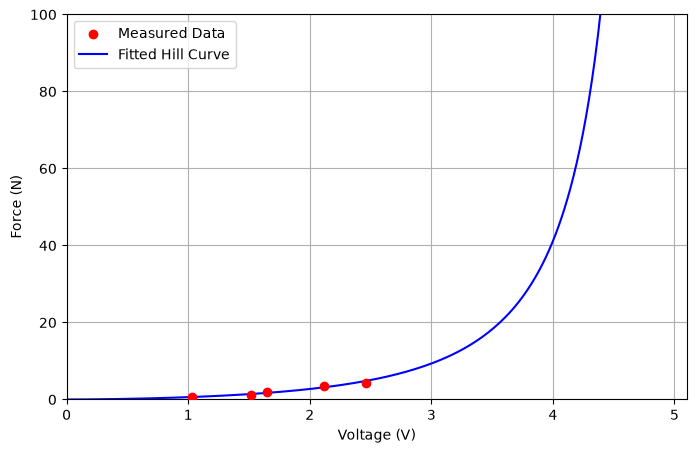

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
#-------------------------------
# Blue (5k)
#-------------------------------

g=9.81
## Three measurements for each weight, the measurements from IDE are ave of 200 samples
#Raw_ADC=np.array([[2349, 2480, 3243], [5616, 4447, 4703], [6737, 6954, 7021], [8840, 9179, 9105], [9829, 9744, 9761]])
#Force=g*np.array([68.8, 123.8, 192.8, 363.4, 497.6])/1000

bit_offset = 98
Raw_ADC=np.array([[3189, 3656, 3288], [5000, 4913, 5031], [5733, 5399, 5071], [7072, 7011, 6739], [8103, 7949, 8158]])
Force=g*np.array([69, 125, 195, 365, 435])/1000

Raw_ADC_mean = Raw_ADC.mean(axis=1)
Raw_ADC_std = Raw_ADC.std(axis=1)
bit_to_V = (5.0-0-0)/(2**14-0.0)

v_offset = bit_to_V*bit_offset
v = bit_to_V*Raw_ADC_mean

def hill_model(f, k, n):
    v_max = 5.0       # Input voltage
    #v_offset = 321*bit_to_V   # Base voltage 
    return ((v_max - v_offset) * (f ** n)) / ((k ** n) + (f ** n)) + v_offset

#Fit only 2 parameters (k and n) since V_max and offset is fixed.
popt, pcov = curve_fit(hill_model, Force, v, p0=[2.0, 1.0], maxfev=10000)
k, n = popt
print(f"Fitted parameters -> k: {k:.4f}, n: {n:.4f}")

# Calculate Force from a measured Voltage (V_measured)
def voltage_to_force(v):
    v_max = 5.0
    #v_offset = 321*bit_to_V
    # Clip to prevent domain errors if voltage goes out of bounds
    v = np.clip(v, v_offset + 1e-4, v_max - 1e-4)
    return k * ((v - v_offset) / (v_max - v)) ** (1.0 / n)

# Plotting the valid 0-5V response curve
plt.figure(figsize=(8, 5))
plt.scatter(v, Force, color='red', label='Measured Data', zorder=5)

voltage_smooth=np.linspace(0, 5, 200)
force_smooth = voltage_to_force(voltage_smooth)

plt.plot(voltage_smooth, force_smooth, label='Fitted Hill Curve', color='blue')
plt.xlabel('Voltage (V)')
plt.ylabel('Force (N)')
plt.xlim([0, 5.1])
plt.ylim([0, 100])
plt.grid(True)
plt.legend()
plt.show()

Fitted parameters -> k: 7.2505, n: 0.7316


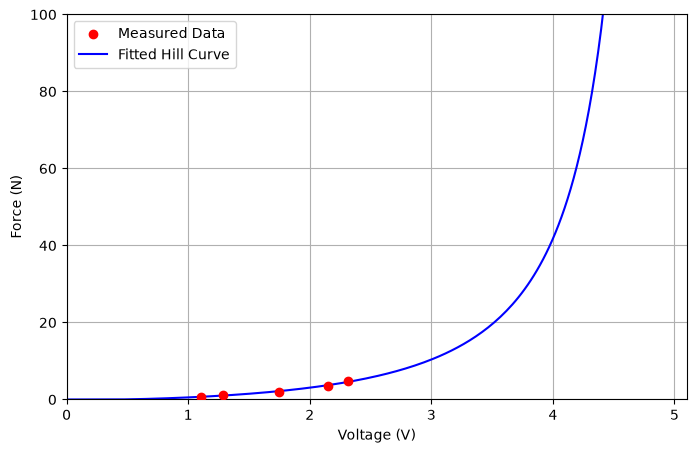

In [ ]:
#-------------------------------
# RED (5k)
#-------------------------------

g=9.81
## Three measurements for each weight, the measurements from IDE are ave of 200 samples
Raw_ADC=np.array([[3705, 3563, 3559], [4434, 4081, 4153], [5592, 5595, 5983], [6960, 7019, 7123], [7896, 7397, 7442]])
Force=g*np.array([69, 125, 193, 365, 489])/1000

bit_offset = 1310
Raw_ADC_mean = Raw_ADC.mean(axis=1)
Raw_ADC_std = Raw_ADC.std(axis=1)
bit_to_V = (5.0-0-0)/(2**14-0.0)

v_offset = bit_to_V*bit_offset
v = bit_to_V*Raw_ADC_mean

def hill_model(f, k, n):
    v_max = 5.0       # Input voltage
    #v_offset = 321*bit_to_V   # Base voltage 
    return ((v_max - v_offset) * (f ** n)) / ((k ** n) + (f ** n)) + v_offset

#Fit only 2 parameters (k and n) since V_max and offset is fixed.
popt, pcov = curve_fit(hill_model, Force, v, p0=[2.0, 1.0], maxfev=10000)
k, n = popt
print(f"Fitted parameters -> k: {k:.4f}, n: {n:.4f}")

# Calculate Force from a measured Voltage (V_measured)
def voltage_to_force(v):
    v_max = 5.0
    #v_offset = 321*bit_to_V
    # Clip to prevent domain errors if voltage goes out of bounds
    v = np.clip(v, v_offset + 1e-4, v_max - 1e-4)
    return k * ((v - v_offset) / (v_max - v)) ** (1.0 / n)

# Plotting the valid 0-5V response curve
plt.figure(figsize=(8, 5))
plt.scatter(v, Force, color='red', label='Measured Data', zorder=5)

voltage_smooth=np.linspace(0, 5, 200)
force_smooth = voltage_to_force(voltage_smooth)

plt.plot(voltage_smooth, force_smooth, label='Fitted Hill Curve', color='blue')
plt.xlabel('Voltage (V)')
plt.ylabel('Force (N)')
plt.xlim([0, 5.1])
plt.ylim([0, 100])
plt.grid(True)
plt.legend()
plt.show()